# DS2002 · ACC Reality Check Starter

**Template — 2026-11-18 · Fall 2026**  

---

## ACC Reality Check: team notebook

Copy this notebook into your team repository and build the project in it. The sections follow the deliverables in the capstone PDF, so a grader can find each part where they expect it. Replace every TODO with your own work, and delete this paragraph when you are done.

Your published API lives in its own folder in the repository (for example `api/main.py`), because PythonAnywhere runs a Python file and not a notebook. Section 6 of this notebook only calls that API and draws a chart from what it returns.

### 0. Team, sources, and setup

**TODO:** list the team members, the two source URLs, and the date of each pull you used for the final results.

**Team:** The Cleaners: Karen Tran and Zach Bernas
**Repository:** https://github.com/karen-tran08/ds2002-acc-reality-check

| Role | Owner |
|---|---|
| Ratings CSV and crosswalk | Karen |
| ESPN pulls and box scores | Zach |
| SQLite schema and queries | Karen |
| API and PythonAnywhere | Zach |

**Sources**

| Source | URL | Pulls used for the final results |
|---|---|---|
| Bart Torvik team ratings (CSV) | https://barttorvik.com/2027_team_results.csv | Two snapshots, dated 2026-11-20 and 2026-11-22 |
| ESPN scoreboard (JSON) | https://site.api.espn.com/apis/site/v2/sports/basketball/mens-college-basketball/scoreboard?groups=2&dates=YYYYMMDD&limit=200 | One file per date, 2026-11-01 through 2026-11-23 |
| ESPN game summary (JSON) | https://site.api.espn.com/apis/site/v2/sports/basketball/mens-college-basketball/summary?event=GAME_ID | One file per finished game: 107 games as of 2026-11-23 |

Torvik returns 403 to scripted requests from Colab, so each snapshot is downloaded in a browser and saved as `data/raw/torvik/torvik_YYYY-MM-DD.csv` using the download date.

In [49]:
# TODO: imports and constants (URLs, the database file name, the raw data folder)

import json, re, time, sqlite3
from pathlib import Path
from datetime import date, datetime, timedelta
from zoneinfo import ZoneInfo

import requests
import pandas as pd
import numpy as np

# Sources
TORVIK_URL = 'https://barttorvik.com/2027_team_results.csv'
ESPN_BASE = 'https://site.api.espn.com/apis/site/v2/sports/basketball/mens-college-basketball'
ESPN_SCOREBOARD_URL = f'{ESPN_BASE}/scoreboard'
ESPN_SUMMARY_URL = f'{ESPN_BASE}/summary'
ACC_ESPN_GROUP = 2
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                         '(KHTML, like Gecko) Chrome/131.0 Safari/537.36'}

# Files
DB_PATH = 'acc.db'
RAW = Path('data/raw')
TORVIK_DIR = RAW / 'torvik'
SCOREBOARD_DIR = RAW / 'scoreboard'
SUMMARY_DIR = RAW / 'summaries'
for folder in (TORVIK_DIR, SCOREBOARD_DIR, SUMMARY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Dates (Colab's clock is UTC, so "today" is taken in Eastern time)
EASTERN = ZoneInfo('America/New_York')
TODAY = datetime.now(EASTERN).date()
SEASON_START = date(2026, 11, 1)

print('Today (ET):', TODAY)
print('Torvik snapshots on disk:', sorted(p.name for p in TORVIK_DIR.glob('*.csv')))


Today (ET): 2026-11-23
Torvik snapshots on disk: ['torvik_2026-11-20.csv', 'torvik_2026-11-22.csv']


In [50]:
# Restore the Torvik snapshots committed to the team repo
REPO_RAW = 'https://raw.githubusercontent.com/karen-tran08/ds2002-acc-reality-check/main/'
SNAPSHOT_DATES = ['2026-11-20', '2026-11-22']   # add each new snapshot date here after committing it

for d in SNAPSHOT_DATES:
    path = TORVIK_DIR / f'torvik_{d}.csv'
    if not path.exists():
        r = requests.get(REPO_RAW + f'data/raw/torvik/torvik_{d}.csv', timeout=30)
        r.raise_for_status()
        path.write_bytes(r.content)
        print('restored', path.name)

### 1. Extract

**TODO:** pull the Torvik CSV and the ESPN scoreboard and summary JSON. Save every raw response to disk, and read from the saved copy when it exists so that a rerun does not call the source again.

In [51]:
# TODO: Torvik ratings snapshot

tv_path = TORVIK_DIR / f'torvik_{TODAY.isoformat()}.csv'
if not tv_path.exists():
    try:
        r = requests.get(TORVIK_URL, headers=HEADERS, timeout=30)
        r.raise_for_status()
        if not r.text.startswith('rank,team'):
            raise ValueError('got a web page instead of the CSV')
        tv_path.write_bytes(r.content)
        print('saved', tv_path.name)
    except Exception as e:
        print(f'Torvik download failed ({e}); using the snapshots already on disk')

torvik_files = sorted(TORVIK_DIR.glob('*.csv'))
assert torvik_files, 'no Torvik snapshot on disk: download one in a browser and upload it'
print('Torvik snapshots:', [f.name for f in torvik_files])


Torvik download failed (403 Client Error: Forbidden for url: https://barttorvik.com/2027_team_results.csv); using the snapshots already on disk
Torvik snapshots: ['torvik_2026-11-20.csv', 'torvik_2026-11-22.csv']


In [52]:
# TODO: ESPN scoreboard, one request per date

finished_ids = set()
d = SEASON_START
while d <= TODAY:
    sb_path = SCOREBOARD_DIR / f'scoreboard_{d:%Y%m%d}.json'
    stale = sb_path.exists() and any(
        not ev['status']['type']['completed']
        for ev in json.loads(sb_path.read_text()).get('events', []))
    if not sb_path.exists() or stale:
        r = requests.get(ESPN_SCOREBOARD_URL,
                         params={'dates': f'{d:%Y%m%d}', 'groups': ACC_ESPN_GROUP, 'limit': 200},
                         timeout=30)
        r.raise_for_status()
        sb_path.write_text(r.text)
        time.sleep(0.5)
    for ev in json.loads(sb_path.read_text()).get('events', []):
        if ev['status']['type']['completed']:
            finished_ids.add(ev['id'])
    d += timedelta(days=1)

In [53]:
# TODO: ESPN game summaries, one request per finished game

for gid in sorted(finished_ids):
    s_path = SUMMARY_DIR / f'summary_{gid}.json'
    if not s_path.exists():
        r = requests.get(ESPN_SUMMARY_URL, params={'event': gid}, timeout=30)
        r.raise_for_status()
        s_path.write_text(r.text)
        time.sleep(0.5)


In [54]:
sb_files = sorted(SCOREBOARD_DIR.glob('*.json'))
summary_files = sorted(SUMMARY_DIR.glob('*.json'))
print('Scoreboard dates saved:', len(sb_files),
      f'({sb_files[0].stem[-8:]} to {sb_files[-1].stem[-8:]})' if sb_files else '')
print('Finished ACC games:', len(finished_ids))
print('Game summaries saved:', len(summary_files))
missing = finished_ids - {p.stem.removeprefix('summary_') for p in summary_files}
print('Finished games missing a summary:', sorted(missing) or 'none')

Scoreboard dates saved: 23 (20261101 to 20261123)
Finished ACC games: 107
Game summaries saved: 107
Finished games missing a summary: none


### 2. Transform

**TODO:** one function or clearly labeled cell per step, each printing a row count.

In [55]:
# TODO: the team name crosswalk, with the unmatched names printed before and after

torvik_files = sorted(TORVIK_DIR.glob('*.csv'))
torvik = pd.read_csv(torvik_files[-1]).drop(columns=['rank.1'], errors='ignore')
torvik_names = set(torvik['team'])

espn_teams = {}
for f in sorted(SCOREBOARD_DIR.glob('*.json')):
    for ev in json.loads(f.read_text()).get('events', []):
        for c in ev['competitions'][0]['competitors']:
            t = c['team']
            espn_teams[t['id']] = {'espn_id': t['id'], 'espn_name': t['location'],
                                   'espn_short': t.get('shortDisplayName'),
                                   'is_acc': int(str(t.get('conferenceId')) == str(ACC_ESPN_GROUP))}
teams = pd.DataFrame(espn_teams.values()).sort_values('espn_name').reset_index(drop=True)

def auto_match(name):
    if name in torvik_names:
        return name
    alt = re.sub(r' State$', ' St.', name)
    return alt if alt in torvik_names else None

teams['torvik_name'] = teams['espn_name'].map(auto_match)
first_miss = teams.loc[teams['torvik_name'].isna(), 'espn_name'].tolist()
print(f'Unmatched after automatic attempt ({len(first_miss)}):', first_miss)

MANUAL = {
    'NC State': 'N.C. State',
    'Miami': 'Miami FL',
    'Loyola Maryland': 'Loyola MD',
    'American University': 'American',
    'Texas A&M-Corpus Christi': 'Texas A&M Corpus Chris',
    'Ole Miss': 'Mississippi',
}
assert set(MANUAL.values()) <= torvik_names, 'a manual fix points to a name Torvik does not use'
fixed = teams['torvik_name'].isna() & teams['espn_name'].isin(MANUAL)
teams.loc[fixed, 'torvik_name'] = teams.loc[fixed, 'espn_name'].map(MANUAL)
teams['match_method'] = 'auto'
teams.loc[fixed, 'match_method'] = 'manual'
teams.loc[teams['torvik_name'].isna(), 'match_method'] = 'unrated (not Division I)'
still_miss = teams.loc[teams['torvik_name'].isna(), 'espn_name'].tolist()
print(f'Manual fixes applied: {int(fixed.sum())}')
print(f'Still unmatched after fixes ({len(still_miss)}):', still_miss)

acc = teams[teams['is_acc'] == 1]
assert len(acc) == 18 and acc['torvik_name'].notna().all(), 'not all 18 ACC schools are matched'
matched = teams['torvik_name'].dropna()
assert matched.is_unique, f'two ESPN teams share a Torvik row: {matched[matched.duplicated()].tolist()}'
assert set(acc['torvik_name']) == set(torvik.loc[torvik['conf'] == 'ACC', 'team'])

# team_crosswalk: one row per spelling (ESPN location, ESPN short name, Torvik name) -> ESPN id
team_crosswalk = pd.concat([
    teams[['espn_name', 'espn_id']].rename(columns={'espn_name': 'source_name'}).assign(source='espn'),
    teams[['espn_short', 'espn_id']].rename(columns={'espn_short': 'source_name'}).assign(source='espn_short'),
    teams.dropna(subset=['torvik_name'])[['torvik_name', 'espn_id']]
         .rename(columns={'torvik_name': 'source_name'}).assign(source='torvik'),
], ignore_index=True).drop_duplicates(['source', 'source_name'])[['source', 'source_name', 'espn_id']]

# ratings: every Division I team, one row per snapshot
rating_frames = []
for f in torvik_files:
    snap = pd.read_csv(f)
    wl = snap['record'].str.split('-', expand=True).astype(int)
    rating_frames.append(pd.DataFrame({
        'snapshot_date': re.search(r'\d{4}-\d{2}-\d{2}', f.stem)[0],
        'torvik_name': snap['team'], 'conf': snap['conf'], 'rank': snap['rank'],
        'wins': wl[0], 'losses': wl[1], 'adjoe': snap['adjoe'], 'adjde': snap['adjde'],
        'barthag': snap['barthag'], 'adjt': snap['adjt'], 'sos': snap['sos'],
        'ncsos': snap['ncsos'], 'wab': snap['WAB']}))
ratings = pd.concat(rating_frames, ignore_index=True)

print(f'\nteams: {len(teams)} rows | team_crosswalk: {len(team_crosswalk)} rows | ratings: {len(ratings)} rows')

Unmatched after automatic attempt (7): ['Adams State', 'American University', 'Loyola Maryland', 'Miami', 'NC State', 'Ole Miss', 'Texas A&M-Corpus Christi']
Manual fixes applied: 6
Still unmatched after fixes (1): ['Adams State']

teams: 116 rows | team_crosswalk: 347 rows | ratings: 730 rows


In [56]:
# TODO: games, with the Eastern game date derived from the UTC start time

game_rows, unfinished = {}, set()
for f in sorted(SCOREBOARD_DIR.glob('*.json')):
    for ev in json.loads(f.read_text()).get('events', []):
        if not ev['status']['type']['completed']:
            unfinished.add(ev['id'])
            continue
        comp = ev['competitions'][0]
        side = {c['homeAway']: c for c in comp['competitors']}
        game_rows[ev['id']] = {
            'game_id': ev['id'], 'start_utc': ev['date'],
            'home_id': side['home']['team']['id'], 'away_id': side['away']['team']['id'],
            'home_score': int(side['home']['score']), 'away_score': int(side['away']['score']),
            'neutral_site': int(bool(comp.get('neutralSite'))),
            'conference_game': int(bool(comp.get('conferenceCompetition')))}
games = pd.DataFrame(game_rows.values())
start = pd.to_datetime(games['start_utc'], utc=True)
games['game_date_et'] = start.dt.tz_convert(EASTERN).dt.strftime('%Y-%m-%d')
games_date_moved = int((start.dt.strftime('%Y-%m-%d') != games['game_date_et']).sum())
unfinished_dropped = len(unfinished - set(game_rows))
unrated_ids = set(teams.loc[teams['torvik_name'].isna(), 'espn_id'])
games_vs_unrated = int((games['home_id'].isin(unrated_ids) | games['away_id'].isin(unrated_ids)).sum())
print(f'games: {len(games)} rows | unfinished dropped: {unfinished_dropped} | '
      f'date moved by UTC->ET: {games_date_moved} | vs unrated opponents: {games_vs_unrated}')

games: 107 rows | unfinished dropped: 3 | date moved by UTC->ET: 77 | vs unrated opponents: 1


In [57]:
# TODO: team_games, one row per team per game, with margin and possessions

def made_att(text):
    """'25-60' -> (25, 60); '--' or blank -> (0, 0)"""
    parts = str(text).split('-')
    if len(parts) != 2 or not parts[0].strip().isdigit():
        return 0, 0
    return int(parts[0]), int(parts[1])

def to_int(x):
    try:
        return int(float(x))
    except (TypeError, ValueError):
        return 0

box_rows = []
for gid in games['game_id']:
    summary = json.loads((SUMMARY_DIR / f'summary_{gid}.json').read_text())
    for t in summary['boxscore']['teams']:
        s = {st['name']: st['displayValue'] for st in t['statistics']}
        fgm, fga = made_att(s['fieldGoalsMade-fieldGoalsAttempted'])
        fg3m, fg3a = made_att(s['threePointFieldGoalsMade-threePointFieldGoalsAttempted'])
        ftm, fta = made_att(s['freeThrowsMade-freeThrowsAttempted'])
        box_rows.append({
            'game_id': gid, 'espn_id': t['team']['id'],
            'fgm': fgm, 'fga': fga, 'fg3m': fg3m, 'fg3a': fg3a, 'ftm': ftm, 'fta': fta,
            'oreb': to_int(s.get('offensiveRebounds')), 'dreb': to_int(s.get('defensiveRebounds')),
            'reb': to_int(s.get('totalRebounds')), 'ast': to_int(s.get('assists')),
            'stl': to_int(s.get('steals')), 'blk': to_int(s.get('blocks')),
            'tov': to_int(s.get('totalTurnovers', s.get('turnovers'))), 'pf': to_int(s.get('fouls'))})
box = pd.DataFrame(box_rows)

home = games.assign(espn_id=games['home_id'], opponent_id=games['away_id'],
                    points_for=games['home_score'], points_against=games['away_score'],
                    site=np.where(games['neutral_site'] == 1, 'neutral', 'home'))
away = games.assign(espn_id=games['away_id'], opponent_id=games['home_id'],
                    points_for=games['away_score'], points_against=games['home_score'],
                    site=np.where(games['neutral_site'] == 1, 'neutral', 'away'))
team_games = pd.concat([home, away], ignore_index=True)[
    ['game_id', 'espn_id', 'opponent_id', 'game_date_et', 'site', 'conference_game',
     'points_for', 'points_against']]
team_games['margin'] = team_games['points_for'] - team_games['points_against']
team_games['win'] = (team_games['margin'] > 0).astype(int)
team_games = team_games.merge(box, on=['game_id', 'espn_id'], how='left', validate='one_to_one')

# possessions = FGA - OREB + TO + 0.475 * FTA, averaged across the two teams in the game
team_games['poss_team'] = team_games['fga'] - team_games['oreb'] + team_games['tov'] + 0.475 * team_games['fta']
team_games['possessions'] = team_games.groupby('game_id')['poss_team'].transform('mean').round(1)
team_games = team_games.drop(columns='poss_team')

missing_box = int(team_games['fga'].isna().sum())
assert len(team_games) == 2 * len(games), 'every game should appear exactly twice'
print(f'team_games: {len(team_games)} rows | rows without a box score: {missing_box}')

team_games: 214 rows | rows without a box score: 0


In [58]:
# TODO: player_games

player_rows, dnp_dropped = [], 0
for gid in games['game_id']:
    summary = json.loads((SUMMARY_DIR / f'summary_{gid}.json').read_text())
    for side in summary['boxscore'].get('players', []):
        block = side['statistics'][0]
        cols = [c.upper() for c in (block.get('names') or block.get('labels'))]
        for a in block['athletes']:
            if a.get('didNotPlay') or not a.get('stats'):
                dnp_dropped += 1
                continue
            st = dict(zip(cols, a['stats']))
            fgm, fga = made_att(st['FG'])
            fg3m, fg3a = made_att(st['3PT'])
            ftm, fta = made_att(st['FT'])
            player_rows.append({
                'game_id': gid, 'player_id': a['athlete']['id'],
                'player_name': a['athlete']['displayName'], 'espn_id': side['team']['id'],
                'starter': int(bool(a.get('starter'))), 'minutes': to_int(st.get('MIN')),
                'points': to_int(st.get('PTS')), 'fgm': fgm, 'fga': fga, 'fg3m': fg3m, 'fg3a': fg3a,
                'ftm': ftm, 'fta': fta, 'oreb': to_int(st.get('OREB')), 'dreb': to_int(st.get('DREB')),
                'rebounds': to_int(st.get('REB')), 'assists': to_int(st.get('AST')),
                'steals': to_int(st.get('STL')), 'blocks': to_int(st.get('BLK')),
                'turnovers': to_int(st.get('TO')), 'fouls': to_int(st.get('PF'))})
player_games = pd.DataFrame(player_rows)
assert not player_games.duplicated(['game_id', 'player_id']).any()

# Check: player points add up to the team score
pts_check = player_games.groupby(['game_id', 'espn_id'])['points'].sum().reset_index() \
    .merge(team_games[['game_id', 'espn_id', 'points_for']], on=['game_id', 'espn_id'])
pts_mismatch = int((pts_check['points'] != pts_check['points_for']).sum())
print(f'player_games: {len(player_games)} rows | did-not-play rows dropped: {dnp_dropped} | '
      f'team totals that do not match the score: {pts_mismatch}')


player_games: 2409 rows | did-not-play rows dropped: 899 | team totals that do not match the score: 1


### 3. Load into SQLite

**TODO:** create the tables with primary keys, load them so that a rerun cannot duplicate rows, and print the row count of every table.

In [59]:
SCHEMA = """
CREATE TABLE IF NOT EXISTS teams (
    espn_id      TEXT PRIMARY KEY,
    espn_name    TEXT NOT NULL,
    espn_short   TEXT,
    torvik_name  TEXT,            -- NULL = not Division I, no rating
    match_method TEXT NOT NULL,
    is_acc       INTEGER NOT NULL
);
CREATE TABLE IF NOT EXISTS team_crosswalk (
    source       TEXT NOT NULL,   -- 'espn', 'espn_short' or 'torvik'
    source_name  TEXT NOT NULL,
    espn_id      TEXT NOT NULL REFERENCES teams(espn_id),
    PRIMARY KEY (source, source_name)
);
CREATE TABLE IF NOT EXISTS ratings (
    snapshot_date TEXT NOT NULL,
    torvik_name   TEXT NOT NULL,
    conf          TEXT,
    rank          INTEGER,
    wins          INTEGER,
    losses        INTEGER,
    adjoe         REAL,
    adjde         REAL,
    barthag       REAL,
    adjt          REAL,
    sos           REAL,
    ncsos         REAL,
    wab           REAL,
    PRIMARY KEY (snapshot_date, torvik_name)
);
CREATE TABLE IF NOT EXISTS games (
    game_id         TEXT PRIMARY KEY,
    game_date_et    TEXT NOT NULL,
    start_utc       TEXT NOT NULL,
    home_id         TEXT NOT NULL REFERENCES teams(espn_id),
    away_id         TEXT NOT NULL REFERENCES teams(espn_id),
    home_score      INTEGER NOT NULL,
    away_score      INTEGER NOT NULL,
    neutral_site    INTEGER NOT NULL,
    conference_game INTEGER NOT NULL
);
CREATE TABLE IF NOT EXISTS team_games (
    game_id         TEXT NOT NULL REFERENCES games(game_id),
    espn_id         TEXT NOT NULL REFERENCES teams(espn_id),
    opponent_id     TEXT NOT NULL REFERENCES teams(espn_id),
    game_date_et    TEXT NOT NULL,
    site            TEXT NOT NULL,   -- 'home', 'away' or 'neutral'
    conference_game INTEGER NOT NULL,
    points_for      INTEGER NOT NULL,
    points_against  INTEGER NOT NULL,
    margin          INTEGER NOT NULL,
    win             INTEGER NOT NULL,
    fgm INTEGER, fga INTEGER, fg3m INTEGER, fg3a INTEGER, ftm INTEGER, fta INTEGER,
    oreb INTEGER, dreb INTEGER, reb INTEGER, ast INTEGER, stl INTEGER, blk INTEGER,
    tov INTEGER, pf INTEGER,
    possessions     REAL,
    PRIMARY KEY (game_id, espn_id)
);
CREATE TABLE IF NOT EXISTS player_games (
    game_id     TEXT NOT NULL REFERENCES games(game_id),
    player_id   TEXT NOT NULL,
    player_name TEXT NOT NULL,
    espn_id     TEXT NOT NULL REFERENCES teams(espn_id),
    starter     INTEGER NOT NULL,
    minutes     INTEGER,
    points      INTEGER,
    fgm INTEGER, fga INTEGER, fg3m INTEGER, fg3a INTEGER, ftm INTEGER, fta INTEGER,
    oreb INTEGER, dreb INTEGER, rebounds INTEGER, assists INTEGER,
    steals INTEGER, blocks INTEGER, turnovers INTEGER, fouls INTEGER,
    PRIMARY KEY (game_id, player_id)
);
"""

TABLES = {'teams': teams, 'team_crosswalk': team_crosswalk, 'ratings': ratings,
          'games': games, 'team_games': team_games, 'player_games': player_games}

def load(conn):
    """Upsert every table with INSERT OR REPLACE. Safe to run any number of times."""
    conn.executescript(SCHEMA)
    with conn:
        for table, df in TABLES.items():
            cols = [c for c in df.columns
                    if c in {r[1] for r in conn.execute(f'PRAGMA table_info({table})')}]
            sql = (f"INSERT OR REPLACE INTO {table} ({', '.join(cols)}) "
                   f"VALUES ({', '.join('?' * len(cols))})")
            rows = df[cols].astype(object).where(df[cols].notna(), None).itertuples(index=False)
            conn.executemany(sql, rows)

def row_counts(conn):
    return {t: conn.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0] for t in TABLES}

conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA foreign_keys = ON')
load(conn)

for (sql,) in conn.execute("SELECT sql FROM sqlite_master WHERE type = 'table'"):
    print(sql, end='\n\n')
counts_first = row_counts(conn)
print('Row counts after first load: ', counts_first)

CREATE TABLE teams (
    espn_id      TEXT PRIMARY KEY,
    espn_name    TEXT NOT NULL,
    espn_short   TEXT,
    torvik_name  TEXT,            -- NULL = not Division I, no rating
    match_method TEXT NOT NULL,
    is_acc       INTEGER NOT NULL
)

CREATE TABLE team_crosswalk (
    source       TEXT NOT NULL,   -- 'espn', 'espn_short' or 'torvik'
    source_name  TEXT NOT NULL,
    espn_id      TEXT NOT NULL REFERENCES teams(espn_id),
    PRIMARY KEY (source, source_name)
)

CREATE TABLE ratings (
    snapshot_date TEXT NOT NULL,
    torvik_name   TEXT NOT NULL,
    conf          TEXT,
    rank          INTEGER,
    wins          INTEGER,
    losses        INTEGER,
    adjoe         REAL,
    adjde         REAL,
    barthag       REAL,
    adjt          REAL,
    sos           REAL,
    ncsos         REAL,
    wab           REAL,
    PRIMARY KEY (snapshot_date, torvik_name)
)

CREATE TABLE games (
    game_id         TEXT PRIMARY KEY,
    game_date_et    TEXT NOT NULL,
    start_utc  

In [60]:
# TODO: load, then prove that a second run leaves the counts unchanged

load(conn)
counts_second = row_counts(conn)
print('Row counts after first load: ', counts_first)
print('Row counts after second load:', counts_second)
assert counts_first == counts_second, 'row counts changed: the load is appending duplicates'

problems = conn.execute('PRAGMA foreign_key_check').fetchall()
assert not problems, f'rows point to ids that do not exist: {problems[:5]}'
print('Rerun test passed: every count is unchanged, and every id points to a real row.')

Row counts after first load:  {'teams': 116, 'team_crosswalk': 347, 'ratings': 730, 'games': 107, 'team_games': 214, 'player_games': 2409}
Row counts after second load: {'teams': 116, 'team_crosswalk': 347, 'ratings': 730, 'games': 107, 'team_games': 214, 'player_games': 2409}
Rerun test passed: every count is unchanged, and every id points to a real row.


### 4. Questions

Each question gets a SQL query run against your database, a chart if the PDF asks for one, and an answer written in full sentences that includes the number it rests on.

#### Q1. Record versus rating

In [61]:
# TODO: SQL

def sql(query, params=()):
    return pd.read_sql_query(query, conn, params=params)

LATEST = conn.execute('SELECT MAX(snapshot_date) FROM ratings').fetchone()[0]
print('Newest ratings snapshot:', LATEST)

q1 = sql("""
WITH rec AS (
    SELECT espn_id, COUNT(*) AS games, SUM(win) AS wins
    FROM team_games GROUP BY espn_id
)
SELECT t.espn_name AS team,
       rec.games, rec.wins, rec.games - rec.wins AS losses,
       ROUND(1.0 * rec.wins / rec.games, 3)           AS win_pct,
       r.wins || '-' || r.losses                      AS torvik_record,
       rec.games - (r.wins + r.losses)                AS games_not_in_torvik,
       ROUND(r.adjoe - r.adjde, 1)                    AS eff_margin,
       RANK() OVER (ORDER BY 1.0 * rec.wins / rec.games DESC) AS win_rank,
       RANK() OVER (ORDER BY r.adjoe - r.adjde DESC)          AS margin_rank
FROM teams t
JOIN rec USING (espn_id)
JOIN ratings r ON r.torvik_name = t.torvik_name AND r.snapshot_date = ?
WHERE t.is_acc = 1
ORDER BY eff_margin DESC
""", (LATEST,))
q1['record_vs_play'] = q1['margin_rank'] - q1['win_rank']   # > 0: record ranks above how they played
q1

Newest ratings snapshot: 2026-11-22


,team,games,wins,losses,win_pct,torvik_record,games_not_in_torvik,eff_margin,win_rank,margin_rank,record_vs_play
0,Virginia,7,7,0,1.000,7-0,0,27.1,1,1,0
1,Duke,6,4,2,0.667,4-2,0,26.8,16,2,-14
2,Miami,6,5,1,0.833,5-1,0,23.2,7,3,-4
3,Louisville,4,3,1,0.750,3-1,0,21.3,15,4,-11
4,Virginia Tech,7,6,1,0.857,6-0,1,19.6,5,5,0
5,NC State,6,5,1,0.833,5-1,0,19.5,7,6,-1
6,SMU,6,6,0,1.000,6-0,0,15.8,1,7,6
7,North Carolina,5,4,1,0.800,4-1,0,15.6,13,8,-5
8,Florida State,6,5,1,0.833,5-1,0,15.5,7,9,2
9,Notre Dame,7,6,1,0.857,6-1,0,14.9,5,10,5


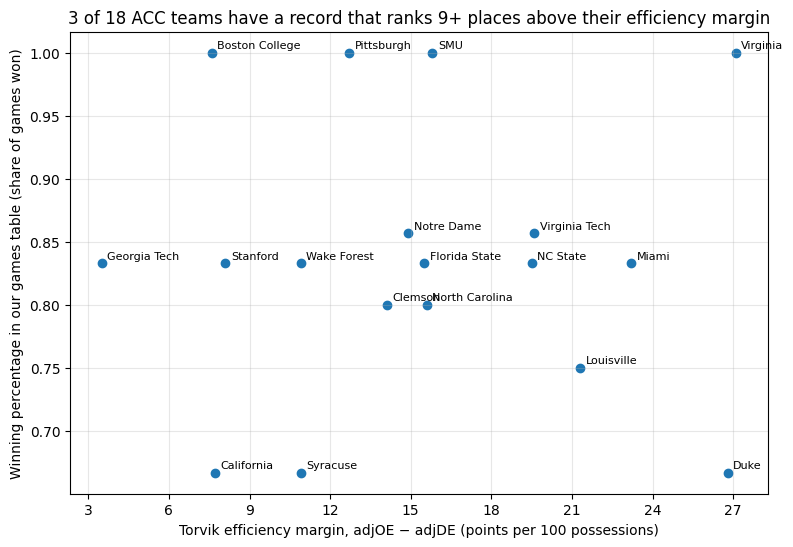

In [62]:
# TODO: chart 1
import matplotlib
import matplotlib.pyplot as plt

over = q1[q1['record_vs_play'] >= 9]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(q1['eff_margin'], q1['win_pct'])
for _, row in q1.iterrows():
    ax.annotate(row['team'], (row['eff_margin'], row['win_pct']),
                xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('Torvik efficiency margin, adjOE − adjDE (points per 100 possessions)')
ax.set_ylabel('Winning percentage in our games table (share of games won)')
ax.set_title(f'{len(over)} of 18 ACC teams have a record that ranks 9+ places above their efficiency margin')
ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.show()

**Q1 answer.** This compares each ACC team's winning percentage in our games table (107 team-games, 4–7 per team, through Nov 22) with its efficiency margin (adjOE − adjDE) in the Nov 22 Torvik snapshot. Win% and margin agree at the top: Virginia is 7-0 and also first by margin (+27.1). But win% alone is a poor guide this early, because four of the 18 teams are unbeaten and eleven more have exactly one loss.

**Records that look better than the play.** Three teams have a record that ranks 9 or more places above their margin. Boston College is 6-0 but 17th by margin (+7.6), a gap of 16 places. Pittsburgh is 6-0 but 12th (+12.7), and Georgia Tech is 5-1 but last in the conference (+3.5, 18th); both gaps are 11 places. Stanford (5-1, +8.1, 15th) just misses the cutoff at 8 places. SMU, the third team our proposal flagged, no longer qualifies: it is 6-0 and its margin rose to +15.8 (7th), only 6 places below its record.

**Records that look worse than the play.** Duke is the clearest case the other way: 4-2 (.667, tied for 16th in win%) but second in the ACC by margin at +26.8, a gap of 14 places. Louisville (3-1, +21.3, 4th by margin, 15th by win%) has an 11-place gap. North Carolina (4-1, +15.6, 8th) and Miami (5-1, +23.2, 3rd) also rank 4 to 5 places higher by margin than by record. Their losses came while they were outscoring opponents by a wide margin per possession, which suggests their records understate how well they have played.

**Game counts.** Our count matches the Torvik record for 16 of 18 teams. Virginia Tech (7 games vs. Torvik's 6-0) and Boston College (6 games vs. 5-0) each have one extra game because both played on Nov 22, after that day's snapshot was downloaded. Boston College beat NJIT 79–59, but Virginia Tech lost 106–80 at Oklahoma State, so Virginia Tech's margin in the snapshot is likely higher than it will be once that loss is counted.

With only 4 to 7 games per team, one result can move a team several places in win%, so these gaps are early signals rather than settled conclusions. We will rerun this with the December data.

#### Q2. Strength of the opponents so far

In [63]:
# TODO: SQL

q2 = sql("""
SELECT t.espn_name AS team,
       COUNT(*)                          AS games,
       SUM(ro.barthag IS NULL)           AS unrated_opponents,
       ROUND(AVG(ro.barthag), 3)         AS avg_opp_barthag,
       ROUND(rt.sos, 3)                  AS torvik_sos,
       RANK() OVER (ORDER BY AVG(ro.barthag) DESC) AS our_rank,
       RANK() OVER (ORDER BY rt.sos DESC)          AS torvik_rank
FROM team_games tg
JOIN teams t  ON t.espn_id = tg.espn_id
JOIN teams o  ON o.espn_id = tg.opponent_id
LEFT JOIN ratings ro ON ro.torvik_name = o.torvik_name AND ro.snapshot_date = ?
JOIN ratings rt      ON rt.torvik_name = t.torvik_name AND rt.snapshot_date = ?
WHERE t.is_acc = 1
GROUP BY t.espn_id
ORDER BY avg_opp_barthag DESC
""", (LATEST, LATEST))
q2['rank_gap'] = q2['our_rank'] - q2['torvik_rank']
q2

,team,games,unrated_opponents,avg_opp_barthag,torvik_sos,our_rank,torvik_rank,rank_gap
0,Notre Dame,7,0,0.562,0.547,1,1,0
1,NC State,6,0,0.541,0.495,2,4,-2
2,California,6,1,0.534,0.413,3,10,-7
3,Duke,6,0,0.521,0.495,4,3,1
4,North Carolina,5,0,0.521,0.460,5,5,0
5,Virginia Tech,7,0,0.518,0.431,6,7,-1
6,Pittsburgh,6,0,0.518,0.496,7,2,5
7,Stanford,6,0,0.480,0.434,8,6,2
8,Virginia,7,0,0.451,0.418,9,9,0
9,Syracuse,6,0,0.451,0.423,10,8,2


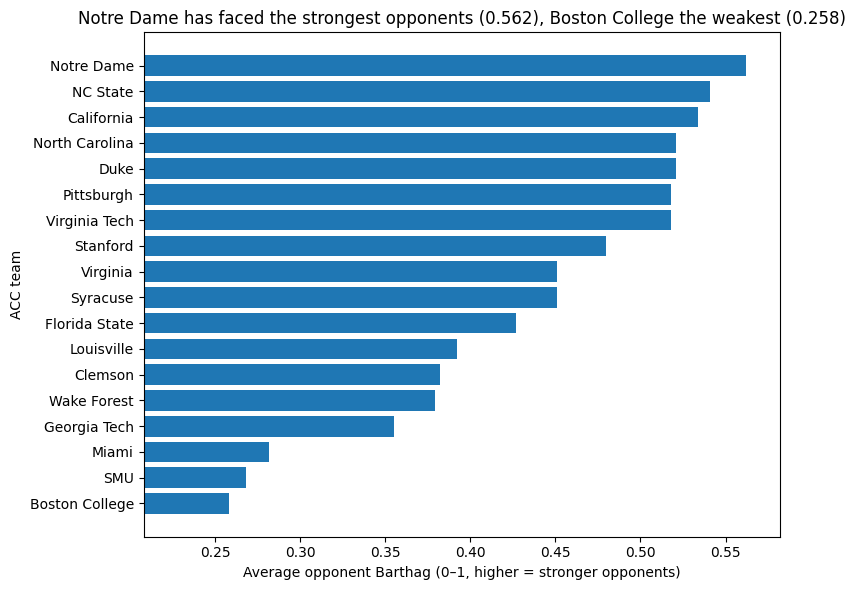

In [64]:
# TODO: chart 2

s = q2.sort_values('avg_opp_barthag')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(s['team'], s['avg_opp_barthag'])
hard, easy = q2.iloc[0], q2.iloc[-1]
ax.set_xlabel('Average opponent Barthag (0–1, higher = stronger opponents)')
ax.set_ylabel('ACC team')
ax.set_title(f"{hard['team']} has faced the strongest opponents ({hard['avg_opp_barthag']:.3f}), "
             f"{easy['team']} the weakest ({easy['avg_opp_barthag']:.3f})")
ax.set_xlim(s['avg_opp_barthag'].min() - 0.05, s['avg_opp_barthag'].max() + 0.02)
plt.tight_layout()
plt.show()

**Q2 answer.** We averaged the Nov 22 Barthag of every opponent each ACC team has played (107 team-games, 4–7 per team, through Nov 22). Notre Dame has faced the strongest schedule (average opponent Barthag 0.562 over 7 games), followed by NC State (0.541, 6 games) and California (0.534, 6 games). Boston College has faced the weakest (0.258), with SMU (0.268) and Miami (0.282) just above it. The strongest schedule's opponents rate more than twice as highly as the weakest's.

**Unrated opponents.** Only one ACC game involved an opponent with no rating: California's Nov 2 game against Adams State, which is not Division I. Every other team's average covers all of its games.

**Comparison with Torvik's SOS.** The two rankings largely agree. 12 of 18 teams are within one place of their Torvik SOS rank, the top team (Notre Dame) is the same in both, and the bottom three are the same three teams (Boston College, SMU and Miami), in a slightly different order. Our averages run higher than Torvik's SOS for every team except Boston College (for example, 0.562 vs. 0.547 for Notre Dame), so the two numbers are on different scales and only the rankings should be compared directly.

**Where they disagree.** The biggest gap is California, 3rd in our ranking (0.534) but 10th by Torvik (0.413). California is also the only team with an unrated opponent. Our average leaves that game out, so it rests on the 5 rated opponents and drops California's weakest one. Torvik's SOS likely still counts that game as a very weak opponent, which pulls California down. The second-biggest gap goes the other way: Pittsburgh is 7th in ours (0.518) but 2nd by Torvik (0.496). NC State, Stanford, Syracuse and Boston College differ by 2 places each.

**What it means.** Boston College and SMU, two of the unbeaten teams whose records looked better than their play in Q1, have played the two weakest schedules in the ACC. That supports our hypothesis that their records are built on easy opponents. Georgia Tech has the fourth-weakest schedule (0.355) and has now lost once. Pittsburgh is the exception: also 6-0 with a modest efficiency margin, but against a middle-of-the-pack schedule by our measure and the second-hardest by Torvik's, so its record is not explained by weak opponents. With only 4 to 7 games per team, one strong or weak opponent can move an average noticeably, so these rankings will shift as conference play begins.

#### Q3. Close games and recent form

In [65]:
# TODO: SQL, including a window function for the rolling margin

q3_close = sql("""
SELECT t.espn_name AS team,
       COUNT(*)                                             AS games,
       SUM(win)                                             AS wins,
       SUM(CASE WHEN ABS(margin) <= 5 AND win = 1 THEN 1 ELSE 0 END) AS close_wins,
       SUM(CASE WHEN ABS(margin) <= 5 AND win = 0 THEN 1 ELSE 0 END) AS close_losses,
       ROUND(1.0 * SUM(CASE WHEN ABS(margin) <= 5 AND win = 1 THEN 1 ELSE 0 END)
             / NULLIF(SUM(win), 0), 2)                      AS share_of_wins_close
FROM team_games tg JOIN teams t USING (espn_id)
WHERE t.is_acc = 1
GROUP BY t.espn_id
ORDER BY share_of_wins_close DESC
""")

q3_roll = sql("""
SELECT t.espn_name AS team, tg.game_date_et, tg.margin,
       ROUND(AVG(tg.margin) OVER (
           PARTITION BY tg.espn_id ORDER BY tg.game_date_et, tg.game_id
           ROWS BETWEEN 4 PRECEDING AND CURRENT ROW), 1) AS rolling5_margin,
       ROW_NUMBER() OVER (PARTITION BY tg.espn_id ORDER BY tg.game_date_et, tg.game_id) AS game_no
FROM team_games tg JOIN teams t USING (espn_id)
WHERE t.is_acc = 1
ORDER BY team, game_no
""")

# Trend: latest rolling-5 margin compared with the team's season-average margin
trend = q3_roll.groupby('team').agg(season_avg=('margin', 'mean'),
                                     latest_rolling5=('rolling5_margin', 'last')).round(1)
trend['trend'] = (trend['latest_rolling5'] - trend['season_avg']).round(1)
q3_close.merge(trend, left_on='team', right_index=True).sort_values('trend', ascending=False)

,team,games,wins,close_wins,close_losses,share_of_wins_close,season_avg,latest_rolling5,trend
13,Miami,6,5,0,0,0.00,32.5,41.0,8.5
7,SMU,6,6,1,0,0.17,24.7,27.0,2.3
14,Clemson,5,4,0,0,0.00,13.2,13.2,0.0
16,North Carolina,5,4,0,0,0.00,13.6,13.6,0.0
10,Louisville,4,3,0,0,0.00,14.5,14.5,0.0
4,Stanford,6,5,1,0,0.20,9.0,9.0,0.0
0,Notre Dame,7,6,2,0,0.33,14.3,14.2,-0.1
17,NC State,6,5,0,0,0.00,15.0,14.2,-0.8
9,Virginia,7,7,1,0,0.14,24.7,23.8,-0.9
1,Syracuse,6,4,1,1,0.25,10.2,9.0,-1.2


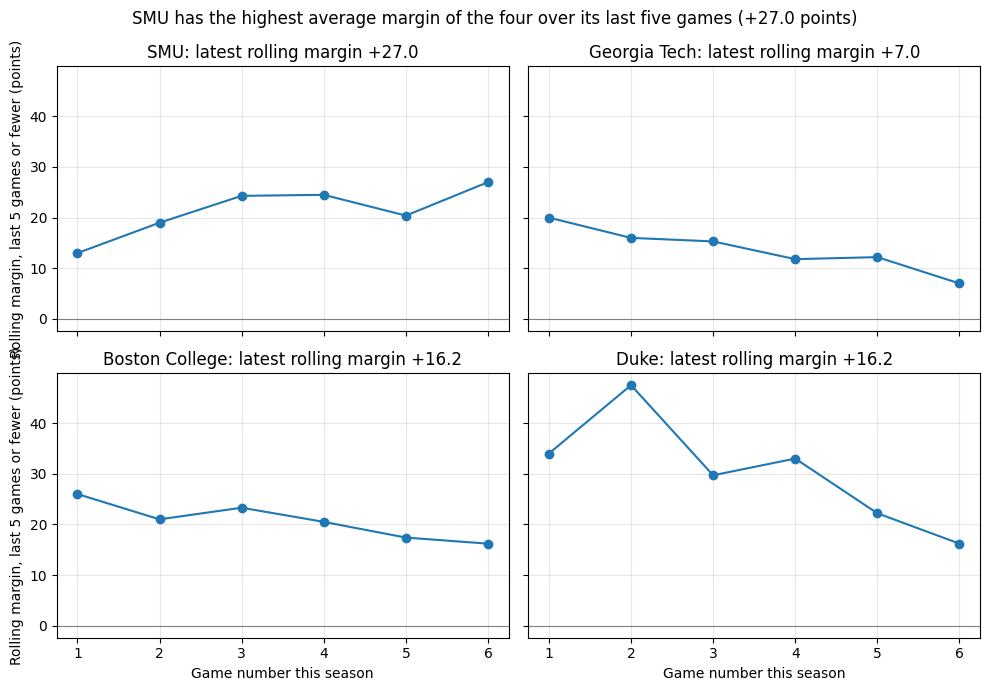

In [66]:
# TODO: chart 3

CHART3_TEAMS = ['SMU', 'Georgia Tech', 'Boston College', 'Duke']   # the proposal's four teams
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, name in zip(axes.flat, CHART3_TEAMS):
    d = q3_roll[q3_roll['team'] == name]
    ax.axhline(0, color='grey', lw=0.8)
    ax.plot(d['game_no'], d['rolling5_margin'], marker='o')
    ax.set_title(f"{name}: latest rolling margin {d['rolling5_margin'].iloc[-1]:+.1f}" if len(d) else name)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel('Game number this season')
for ax in axes[:, 0]:
    ax.set_ylabel('Rolling margin, last 5 games or fewer (points)')
best = trend.loc[CHART3_TEAMS, 'latest_rolling5'].idxmax()
fig.suptitle(f"{best} has the highest average margin of the four over its last five games "
             f"({trend.loc[best, 'latest_rolling5']:+.1f} points)")
plt.tight_layout()
plt.show()

**Q3 answer.** Close games (decided by 5 points or fewer) have been rare so far: 12 of the 107 ACC team-games through Nov 22, made up of 11 close wins and 1 close loss.

**Records that depend on close wins.** No ACC record rests heavily on close wins yet. Notre Dame relies on them most, with 2 of its 6 wins (33%) by 5 points or fewer; if both had gone the other way it would be 4-3 instead of 6-1. Syracuse and Duke each have 1 close win among their 4 wins (25%); Duke's came against Washington State (78–74) and Syracuse's against Lafayette (84–81), both on Nov 21. Georgia Tech, Stanford and Wake Forest each have 1 close win out of 5 (20%), Virginia Tech, SMU and Boston College 1 out of 6 (17%), and Virginia 1 out of 7 (14%). Syracuse has the conference's only close loss. For the teams our proposal flagged, close wins explain little: Georgia Tech won 4 of its 5 wins by more than 5 points, and SMU and Boston College 5 of 6 each, so Q2's weak schedules are the better explanation for their records than close-game luck.

**Trends.** We computed a rolling five-game average margin with a window function and compared each team's latest value with its season average. Three teams (Louisville, Clemson and North Carolina) have played 5 games or fewer, so their latest five-game window is their whole season and no trend can be measured yet. Among the 15 teams with 6–7 games, two are trending up: Miami (+8.5, from a +32.5 season average to +41.0 over its last five) and SMU (+2.3, +24.7 to +27.0). The biggest drop is Virginia Tech (−7.1, +13.7 to +6.6), driven by its 26-point loss at Oklahoma State on Nov 22. Florida State (−4.8), California (−4.1), Pittsburgh (−3.7) and Duke (−3.0) also dropped; the rest are within about 2 points. With only 6–7 games, the window drops just the first one or two games, so most of these changes come from an early blowout leaving the window rather than better or worse recent play. For example, Florida State's first game was a 44-point win over Florida A&M.

**Chart 3.** Of the four proposal teams, SMU has the highest rolling margin (+27.0), ahead of Duke and Boston College (+16.2 each) and Georgia Tech (+7.0). SMU and Boston College are unbeaten, Georgia Tech is 5-1 and Duke is 4-2. With 6 games each, these lines will only show real five-game trends once conference play adds more games, so we will revisit this in December.

#### Q4. Pace and points per possession

In [67]:
# TODO: SQL

q4 = sql("""
SELECT t.espn_name AS team,
       COUNT(*)                                            AS games,
       ROUND(AVG(tg.possessions), 1)                        AS poss_per_game,
       ROUND(r.adjt, 1)                                     AS torvik_adjt,
       ROUND(100.0 * SUM(tg.points_for)     / SUM(tg.possessions), 1) AS raw_off_eff,
       ROUND(r.adjoe, 1)                                    AS torvik_adjoe,
       ROUND(100.0 * SUM(tg.points_against) / SUM(tg.possessions), 1) AS raw_def_eff,
       ROUND(r.adjde, 1)                                    AS torvik_adjde
FROM team_games tg
JOIN teams t   USING (espn_id)
JOIN ratings r ON r.torvik_name = t.torvik_name AND r.snapshot_date = ?
WHERE t.is_acc = 1
GROUP BY t.espn_id
""", (LATEST,))
q4['raw_margin'] = (q4['raw_off_eff'] - q4['raw_def_eff']).round(1)
q4['adj_margin'] = (q4['torvik_adjoe'] - q4['torvik_adjde']).round(1)
q4['raw_minus_adj'] = (q4['raw_margin'] - q4['adj_margin']).round(1)   # > 0: looks better raw than adjusted
q4.sort_values('raw_minus_adj', ascending=False)

,team,games,poss_per_game,torvik_adjt,raw_off_eff,torvik_adjoe,raw_def_eff,torvik_adjde,raw_margin,adj_margin,raw_minus_adj
0,Boston College,6,62.1,63.0,120.4,113.2,91.7,105.6,28.7,7.6,21.1
8,Miami,6,74.5,72.1,119.5,119.3,75.9,96.1,43.6,23.2,20.4
11,SMU,6,73.6,72.1,123.5,116.3,89.9,100.5,33.6,15.8,17.8
6,Pittsburgh,6,72.4,69.5,119.3,113.3,92.4,100.6,26.9,12.7,14.2
14,Florida State,6,72.2,72.3,122.8,115.8,95.1,100.3,27.7,15.5,12.2
4,Wake Forest,6,69.1,68.8,114.8,111.2,94.1,100.3,20.7,10.9,9.8
15,Georgia Tech,6,75.2,72.2,111.9,109.5,99.7,106.0,12.2,3.5,8.7
12,Virginia,7,70.7,70.3,130.7,123.7,95.7,96.5,35.0,27.2,7.8
7,Clemson,5,66.4,66.9,127.7,118.4,107.8,104.2,19.9,14.2,5.7
16,Notre Dame,7,71.2,69.1,123.7,118.0,103.6,103.1,20.1,14.9,5.2


**Q4 answer.** From our box scores (107 ACC team-games, 4–7 per team, through Nov 22) we estimated possessions per game and computed points scored and allowed per 100 possessions, then compared them with Torvik's adjusted values in the Nov 22 snapshot.

**Pace.** Our possession estimates track Torvik's adjusted tempo closely, within about 3 possessions per game for every team. Georgia Tech plays fastest (75.2 possessions per game), followed by Duke (74.8), Miami (74.5) and SMU (73.6). Boston College is by far the slowest at 62.1, more than 4 possessions slower than any other ACC team (Clemson is next at 66.4), which matches Torvik's 63.0.

**Raw vs. adjusted efficiency.** Fifteen of 18 teams look better on raw efficiency margin than on Torvik's adjusted margin. That is expected in November, when most games are non-conference games against weaker opponents. The size of the gap is what matters. Boston College has the largest gap (+21.1): it outscores opponents by 28.7 points per 100 possessions raw but only 7.6 adjusted. Miami is next (+20.4, 43.6 raw vs. 23.2 adjusted), then SMU (+17.8), Pittsburgh (+14.2) and Florida State (+12.2). Miami's defense shows the effect most clearly: it allows 75.9 points per 100 possessions raw, but Torvik's adjusted figure is 96.1.

**What the differences tell us.** The three teams with the weakest schedules in Q2 (Boston College, SMU and Miami) have the three largest raw-minus-adjusted gaps, so much of their raw dominance comes from who they played. Three teams look slightly better adjusted than raw: Duke (−1.3), Louisville (−1.0) and Virginia Tech (−0.2). Duke has the 4th-hardest schedule by our measure; Virginia Tech's raw numbers include its 106–80 loss at Oklahoma State, which the Nov 22 ratings do not yet count. Pittsburgh is the exception: a +14.2 gap even though Torvik rates its schedule 2nd-hardest. This suggests Torvik's early-season ratings rest on more than this season's results, such as preseason expectations, which a raw calculation does not include.

This mostly supports our hypothesis: Boston College and Georgia Tech look strong on raw numbers, but once opponent strength is accounted for, their margins (+7.6 and +3.5) rank 17th and 18th in the ACC. SMU's adjusted margin has risen to +15.8 (7th), so its case is weaker than it was on Nov 20. With 4–7 games per team, a single blowout can move raw efficiency a lot, so the adjusted numbers are the more reliable guide this early.

#### Q5. Who carries each team

In [68]:
# TODO: SQL

q5 = sql("""
WITH player_totals AS (
    SELECT pg.espn_id, pg.player_id, pg.player_name,
           SUM(pg.points) AS points, SUM(pg.rebounds) AS rebounds, COUNT(*) AS games
    FROM player_games pg GROUP BY pg.espn_id, pg.player_id
),
ranked AS (
    SELECT *,
           SUM(points) OVER (PARTITION BY espn_id) AS team_points,
           ROW_NUMBER() OVER (PARTITION BY espn_id ORDER BY points DESC) AS rn
    FROM player_totals
)
SELECT t.espn_name AS team, r.player_name AS leading_scorer, r.games,
       r.points, r.team_points,
       ROUND(100.0 * r.points / r.team_points, 1) AS share_pct
FROM ranked r JOIN teams t USING (espn_id)
WHERE r.rn = 1 AND t.is_acc = 1
ORDER BY share_pct DESC
""")
q5

,team,leading_scorer,games,points,team_points,share_pct
0,Pittsburgh,Baye Ndongo,6,122,518,23.6
1,Virginia Tech,Ben Hammond,7,144,611,23.6
2,Florida State,Sebastian Rancik,6,125,532,23.5
3,California,Nojus Indrusaitis,6,116,497,23.3
4,Wake Forest,Kevair Kennedy,6,103,476,21.6
5,North Carolina,Terrence Brown,5,90,423,21.3
6,Stanford,Nick Townsend,6,95,457,20.8
7,Georgia Tech,Tylis Jordan,6,104,505,20.6
8,Clemson,Ace Buckner,5,85,424,20.0
9,Virginia,Thijs De Ridder,7,129,647,19.9


**Q5 answer.** For each ACC team we summed every player's points across the team's games through Nov 22 (4–7 games per team) and found the player with the most. Leading scorers account for between 16.3% and 23.6% of their team's points, so no ACC team yet depends on one player for even a quarter of its scoring.

**Most dependent on one player.** Pittsburgh's Baye Ndongo (122 of 518 points, 23.6%, 6 games) and Virginia Tech's Ben Hammond (144 of 611, 23.6%, 7 games) carry the largest shares. Florida State's Sebastian Rancik (125 of 532, 23.5%, 6 games) and California's Nojus Indrusaitis (116 of 497, 23.3%, 6 games) are just behind, followed by Wake Forest's Kevair Kennedy (103 of 476, 21.6%). Rancik and Hammond are also the highest-volume scorers, at about 20.8 and 20.6 points per game.

**Most balanced.** Miami is the least dependent on one player: its leading scorer, Shelton Henderson, has 87 of 534 points (16.3%). Syracuse (Kiyan Anthony, 16.4%), Louisville (Flory Bidunga, 16.5%) and SMU (Oziyah Sellers, 17.6%) are similarly balanced, with Duke (Patrick Ngongba II, 18.0%) next. Duke, Miami and Louisville also have three of the four best efficiency margins in the ACC (Q1), so the strongest teams so far are the ones that spread their scoring around.

**The proposal teams.** SMU (17.6%) and Boston College (Zak Smrekar, 18.7%) are in the balanced half of the conference, and Georgia Tech (Tylis Jordan, 20.6%) is in the middle, 8th of 18. None of their records rests on one player, so Q2's weak schedules remain the main explanation for those records.

**Data check.** In one team-game the players' points do not add up to the final score: Western Carolina's box score against Wake Forest on Nov 21 sums to 61 points, but the team scored 63. Western Carolina is not an ACC team, so this does not affect the shares above.

With 4 to 7 games per team, one big scoring night or a missed game can move these shares by a few percentage points, so the ranking in the middle of the table is not yet stable.

#### Q6. Does the rating predict the winner?

In [69]:
# TODO: SQL that uses the latest snapshot taken before each game

q6 = sql("""
WITH g AS (
    SELECT g.*,
           (SELECT MAX(snapshot_date) FROM ratings WHERE snapshot_date < g.game_date_et) AS snap
    FROM games g
),
rated AS (
    SELECT g.game_id, g.game_date_et, g.snap,
           th.espn_name AS home, ta.espn_name AS away,
           rh.barthag AS home_barthag, ra.barthag AS away_barthag,
           g.home_score, g.away_score
    FROM g
    JOIN teams th   ON th.espn_id = g.home_id
    JOIN teams ta   ON ta.espn_id = g.away_id
    JOIN ratings rh ON rh.torvik_name = th.torvik_name AND rh.snapshot_date = g.snap
    JOIN ratings ra ON ra.torvik_name = ta.torvik_name AND ra.snapshot_date = g.snap
    WHERE g.snap IS NOT NULL
)
SELECT *,
       CASE WHEN home_barthag > away_barthag THEN home ELSE away END AS favorite,
       CASE WHEN (home_barthag > away_barthag) = (home_score > away_score) THEN 1 ELSE 0 END AS favorite_won
FROM rated
ORDER BY game_date_et
""")
first_snap = conn.execute('SELECT MIN(snapshot_date) FROM ratings').fetchone()[0]
if len(q6):
    print(f'Games tested: {len(q6)} (played after the first snapshot, {first_snap})')
    print(f"Favorite won: {q6['favorite_won'].sum()} of {len(q6)} = {q6['favorite_won'].mean():.1%}")
else:
    print(f'No games yet were played after a saved snapshot (first snapshot: {first_snap}).')
q6

Games tested: 5 (played after the first snapshot, 2026-11-20)
Favorite won: 4 of 5 = 80.0%


,game_id,game_date_et,snap,home,away,home_barthag,away_barthag,home_score,away_score,favorite,favorite_won
0,401909567,2026-11-21,2026-11-20,Duke,Washington State,0.953931,0.506549,78,74,Duke,1
1,401909730,2026-11-21,2026-11-20,Wake Forest,Western Carolina,0.740560,0.429932,90,63,Wake Forest,1
2,401909719,2026-11-21,2026-11-20,Syracuse,Lafayette,0.793645,0.170894,84,81,Syracuse,1
3,401920381,2026-11-22,2026-11-20,Oklahoma State,Virginia Tech,0.854710,0.873106,106,80,Virginia Tech,0
4,401909556,2026-11-22,2026-11-20,Boston College,NJIT,0.682735,0.144347,79,59,Boston College,1


**Q6 answer (status as of Nov 22).** This question tests whether the team with the higher Barthag, in the latest ratings snapshot taken before the game date, wins the game. We use a strict "before the game date" rule: a snapshot from the morning of a game day may already reflect earlier results and is not counted for games that day. Using a rating published after a game would make the favorite look more accurate than it really was.

**Results so far.** Five ACC games played on Nov 21–22 can be tested, each against the Nov 20 snapshot. The favorite won 4 of the 5 (80%). Duke beat Washington State 78–74, Wake Forest beat Western Carolina 90–63, Syracuse beat Lafayette 84–81, and Boston College beat NJIT 79–59. The one miss was the closest matchup on paper: Virginia Tech (0.873) lost 106–80 at Oklahoma State (0.855). Two of the four favorites that won had a large Barthag edge but won by only 3 or 4 points.

**What it means so far.** Five games are far too few to judge how well the rating predicts winners. The other 102 games in our table were played on or before Nov 20, the date of our first snapshot, so no earlier rating exists for them. Games from Nov 23 onward will be tested against the Nov 22 snapshot, and we will save new snapshots on Nov 24, 27 and 29 and twice a week after that (see the plan for the break). The final answer will report the share of games the favorite won and the number of games tested.

### 5. Decision log

**TODO:** every decision that changed the data, with the number of rows it affected.

In [70]:
# Decision log: every decision that changed the data, with the number of rows it affected

state_rule = int(((teams['match_method'] == 'auto') & (teams['espn_name'] != teams['torvik_name'])).sum())
n_snapshots = ratings['snapshot_date'].nunique()
snapshot_list = ', '.join(sorted(ratings['snapshot_date'].unique()))
same_day_games = int((games['game_date_et'] == LATEST).sum())
acc_teams_short = int((q3_roll.groupby('team').size() <= 5).sum())
q6_excluded = len(games) - len(q6)

# Checks on the snapshots before they are stacked into one ratings table
snap_names = ratings.groupby('snapshot_date')['torvik_name'].apply(set)
names_not_in_every_snapshot = len(set.union(*snap_names) - set.intersection(*snap_names))
snap_games = (ratings.assign(g=ratings['wins'] + ratings['losses'])
              .pivot(index='torvik_name', columns='snapshot_date', values='g'))
new_team_games = int((snap_games.iloc[:, -1] - snap_games.iloc[:, 0]).sum()) if n_snapshots > 1 else 0

decision_log = pd.DataFrame([
    # Sources
    ('Source', 'Torvik returns 403 to Colab, so each snapshot is downloaded in a browser, committed to the repo as '
               'data/raw/torvik/torvik_YYYY-MM-DD.csv, and restored into Colab from the repo '
               f'({n_snapshots} snapshots: {snapshot_list})', len(ratings)),
    ('Source', 'Deleted torvik_2026-11-17.csv: it was byte-identical to the Nov 20 download, not a real snapshot', 365),
    ('Source', 'Added the 2026-11-22 snapshot after checking it is a real new pull and not a copy of Nov 20: '
               f'same columns and same {len(snap_names.iloc[-1])} teams, the same 18 ACC schools, and '
               f'{new_team_games} more team-games in the records than on Nov 20', len(snap_names.iloc[-1])),
    ('Source', 'Scoreboard files that still contain unfinished games are downloaded again on the next run', len(games)),

    # Torvik
    ('Torvik', 'Dropped the duplicate rank.1 column; it equals rank on every row of every snapshot', len(ratings)),
    ('Torvik', 'Split record text like "6-0" into integer wins and losses', len(ratings)),
    ('Torvik', f'Kept ratings for every Division I team in all {n_snapshots} snapshots, not only the ACC, '
               'so opponents have ratings; one row per team per snapshot', len(ratings)),
    ('Torvik', 'Q1, Q2 and Q4 compare against the newest snapshot only '
               f'({LATEST}); older snapshots are kept for Q6', len(q1)),
    # Crosswalk
    ('Crosswalk', 'Matched on ESPN location (e.g. "Florida State") and keyed every table by ESPN team id', len(teams)),
    ('Crosswalk', 'Built from the newest snapshot; Torvik team names that are not identical in every snapshot '
                  '(0 means one crosswalk fits all snapshots)', names_not_in_every_snapshot),
    ('Crosswalk', 'Automatic rule: ESPN "X State" -> Torvik "X St."', state_rule),
    ('Crosswalk', 'Manual fixes: ' + ', '.join(f'{k} -> {v}' for k, v in MANUAL.items()), int(fixed.sum())),
    ('Crosswalk', f'Non-Division I opponents ({", ".join(still_miss)}) kept with no rating: their games count toward '
                  'records but are left out of rating-based averages (Q2) and favorites (Q6)', games_vs_unrated),
    # Games
    ('Games', 'Dropped games ESPN had not marked completed', unfinished_dropped),
    ('Games', 'Converted start times from UTC to America/New_York before taking the game date; '
              'these games moved to the previous day', games_date_moved),
    ('Games', f'Games played on the day of the newest snapshot ({LATEST}) are treated as after it, '
              'so that snapshot does not include them', same_day_games),
    # Team and player games
    ('Team games', 'Reshaped each game into two rows, one per team, with margin and home/away/neutral site', len(team_games)),
    ('Team games', 'Split made-attempted text ("25-60") into numeric columns; "--" or blank becomes 0', len(team_games)),
    ('Team games', 'Possessions = FGA - OREB + TO + 0.475*FTA using ESPN totalTurnovers (includes team turnovers), '
                   'averaged across both teams in the game', len(team_games)),
    ('Player games', 'Dropped players marked didNotPlay', dnp_dropped),
    ('Player games', 'Checked player points against the team score; mismatching team-games', pts_mismatch),
    # Load
    ('Load', 'Primary keys plus INSERT OR REPLACE so a rerun replaces rows instead of adding copies; '
             'rerun test showed identical counts', sum(counts_first.values())),
    # Analysis rules
    ('Q1', 'A record "looks better than the play" when its win% rank is 9+ places above its efficiency-margin rank', len(q1)),
    ('Q3', 'Rolling margin uses all available games when a team has played fewer than 5; '
           'trend = latest rolling margin - season average. Teams with 5 or fewer games show no trend yet', acc_teams_short),
    ('Q6', 'Favorite = higher Barthag in the latest snapshot dated strictly before the game date, so games on '
           'Nov 21-22 use the Nov 20 snapshot and later games use Nov 22; games tested', len(q6)),
    ('Q6', 'Games not tested: played on or before the first snapshot date, or involving an unrated team', q6_excluded),
], columns=['area', 'decision', 'rows_affected'])
decision_log.index = decision_log.index + 1

pd.set_option('display.max_colwidth', None)
print(f'{len(decision_log)} decisions logged')
decision_log


26 decisions logged


,area,decision,rows_affected
1,Source,"Torvik returns 403 to Colab, so each snapshot is downloaded in a browser, committed to the repo as data/raw/torvik/torvik_YYYY-MM-DD.csv, and restored into Colab from the repo (2 snapshots: 2026-11-20, 2026-11-22)",730
2,Source,"Deleted torvik_2026-11-17.csv: it was byte-identical to the Nov 20 download, not a real snapshot",365
3,Source,"Added the 2026-11-22 snapshot after checking it is a real new pull and not a copy of Nov 20: same columns and same 365 teams, the same 18 ACC schools, and 218 more team-games in the records than on Nov 20",365
4,Source,Scoreboard files that still contain unfinished games are downloaded again on the next run,107
5,Torvik,Dropped the duplicate rank.1 column; it equals rank on every row of every snapshot,730
6,Torvik,"Split record text like ""6-0"" into integer wins and losses",730
7,Torvik,"Kept ratings for every Division I team in all 2 snapshots, not only the ACC, so opponents have ratings; one row per team per snapshot",730
8,Torvik,"Q1, Q2 and Q4 compare against the newest snapshot only (2026-11-22); older snapshots are kept for Q6",18
9,Crosswalk,"Matched on ESPN location (e.g. ""Florida State"") and keyed every table by ESPN team id",116
10,Crosswalk,Built from the newest snapshot; Torvik team names that are not identical in every snapshot (0 means one crosswalk fits all snapshots),0


### 6. The published API

**TODO:** the live address, the list of routes, and chart 4, drawn from JSON returned by your own API.

OK   200  https://thecleaners.pythonanywhere.com/teams
OK   200  https://thecleaners.pythonanywhere.com/teams/Duke
OK   200  https://thecleaners.pythonanywhere.com/games?date=2026-11-17
OK   200  https://thecleaners.pythonanywhere.com/matchup?a=Duke&b=Virginia
OK   200  https://thecleaners.pythonanywhere.com/leaders?stat=points
OK   404  https://thecleaners.pythonanywhere.com/teams/Nowhere
OK   400  https://thecleaners.pythonanywhere.com/leaders?stat=dunks

Matchup: Duke is favored
Top scorers: [{'player': 'Money Williams', 'team': 'Boston College', 'games': 3, 'per_game': 21.7}, {'player': 'Sebastian Rancik', 'team': 'Florida State', 'games': 6, 'per_game': 20.8}, {'player': 'Baye Ndongo', 'team': 'Pittsburgh', 'games': 6, 'per_game': 20.3}]


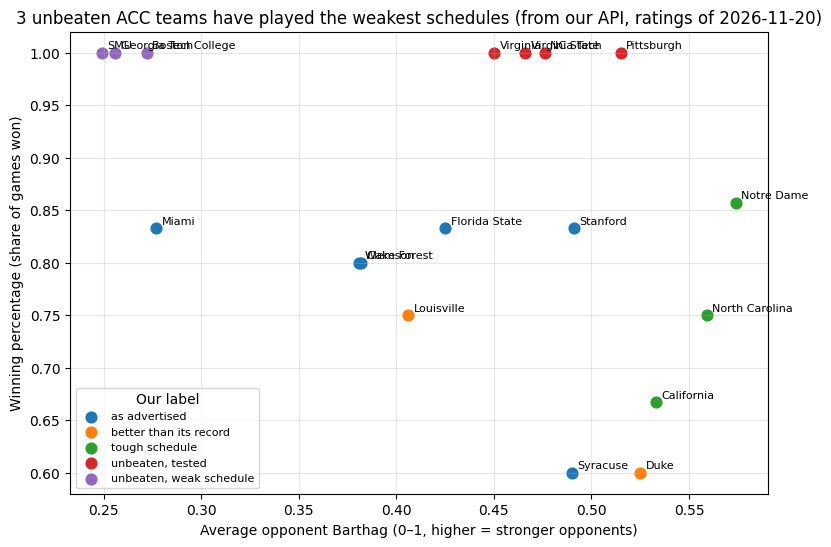

In [71]:
API_URL = 'https://thecleaners.pythonanywhere.com'

# 1. Call every route once, plus the two required error cases
checks = [
    ('/teams',          None,                          200),
    ('/teams/Duke',     None,                          200),
    ('/games',          {'date': '2026-11-17'},        200),
    ('/matchup',        {'a': 'Duke', 'b': 'Virginia'}, 200),
    ('/leaders',        {'stat': 'points'},            200),
    ('/teams/Nowhere',  None,                          404),   # unknown team
    ('/leaders',        {'stat': 'dunks'},             400),   # unknown stat
]
for path, params, expected in checks:
    r = requests.get(API_URL + path, params=params, timeout=30)
    print(f"{'OK  ' if r.status_code == expected else 'FAIL'} {r.status_code}  {r.url}")

# A taste of what two routes return
print('\nMatchup:', requests.get(f'{API_URL}/matchup', params={'a': 'Duke', 'b': 'Virginia'}, timeout=30).json()['favorite'], 'is favored')
print('Top scorers:', requests.get(f'{API_URL}/leaders', params={'stat': 'points', 'limit': 3}, timeout=30).json()['leaders'])

# 2. Chart 4: drawn only from the JSON our API returns
resp = requests.get(f'{API_URL}/teams', timeout=30)
resp.raise_for_status()
api_teams = pd.DataFrame(resp.json()['teams'])

fig, ax = plt.subplots(figsize=(9, 6))
for label, grp in api_teams.groupby('label'):
    ax.scatter(grp['avg_opp_barthag'], grp['win_pct'], label=label, s=60)
for _, row in api_teams.iterrows():
    ax.annotate(row['team'], (row['avg_opp_barthag'], row['win_pct']),
                xytext=(4, 3), textcoords='offset points', fontsize=8)
weak = api_teams[api_teams['label'] == 'unbeaten, weak schedule']
ax.set_xlabel('Average opponent Barthag (0–1, higher = stronger opponents)')
ax.set_ylabel('Winning percentage (share of games won)')
ax.set_title(f'{len(weak)} unbeaten ACC teams have played the weakest schedules '
             f'(from our API, ratings of {resp.json()["ratings_snapshot"]})')
ax.legend(title='Our label', fontsize=8)
ax.grid(alpha=0.3)
plt.show()

### 7. Reflection

**TODO:** answer the five reflection questions from the PDF, with every member contributing.

=

### 8. Presentation video

**TODO:** the link to your team's recorded presentation, which runs no more than eight minutes and includes every member. Put the same link in the README.

_video link here_